# Statevectors

We can make use of the class <code>Statevector</code> to define a state vector of a qubit (in the computational base by default).  
The object <code>Statevector</code> has methods that allows to display the qubit state in **vector notation** or in **ket notation**.  

In [1]:
from qiskit.quantum_info import Statevector
from qiskit.visualization import array_to_latex
from math import sqrt, pi

# Define state vectors in vector notation (Z basis)
state_0 = [1, 0]
state_1 = [0, 1]

# instantiate the Statevector class objects
ket0 = Statevector(state_0)
ket1 = Statevector(state_1)

# Display statevectors in vector notation
print("Statevector ket0 : ",ket0.draw('text'))
print("Statevector ket1 : ",ket1.draw('text'))

Statevector ket0 :  [1.+0.j,0.+0.j]
Statevector ket1 :  [0.+0.j,1.+0.j]


Or equivalently, using latex:

In [2]:
print("Statevector ket0:")
display( array_to_latex(ket0))

print("Statevector ket1:")
display( array_to_latex(ket1))

Statevector ket0:


<IPython.core.display.Latex object>

Statevector ket1:


<IPython.core.display.Latex object>

But it will be better if we can display in ket notation. It is more compact and easy to read:

In [3]:
# Display statevectors in ket notation:

print("Statevector ket0:")
display( ket0.draw('latex'))

print("Statevector ket1:")
display( ket1.draw('latex'))


Statevector ket0:


<IPython.core.display.Latex object>

Statevector ket1:


<IPython.core.display.Latex object>

We can verify other properties of the statevector, such as if it is a valid Statevector.

In [4]:
## define another vector

ket2 = ket0
#ket2 = Statevector([1,1])
#ket2 = Statevector([0.8,0.6])

print("Statevector ket2:")
display(ket2.draw('latex'))

## check is valid
print("Is normalized? : ",ket2.is_valid())     # False


Statevector ket2:


<IPython.core.display.Latex object>

Is normalized? :  True


## The Block Sphere

Let's reoresent the qubitstate on the Block Sphere

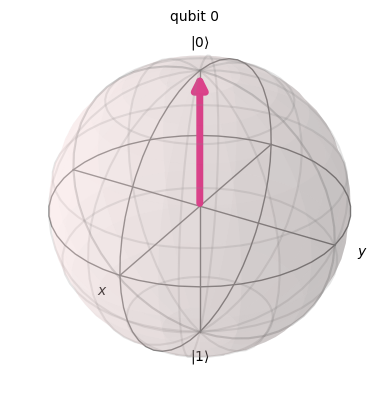

In [5]:
from qiskit.visualization import plot_bloch_multivector

state = ket2 #Statevector
plot_bloch_multivector(state)

# Simple measurements

Let's define a valid mixed state vector and do some measurements using the Statevector methods.  
The method```measure()``` returns the result of measurement and the remaining state vector.   
Remember that measurements are probabilistic, so runnig the same cell may output different results:

In [6]:
ket3_mix = Statevector([1/sqrt(2),1/sqrt(2)])

## Normalisation
display(ket3_mix.draw('latex'))
print("Is normalized? : ",ket3_mix.is_valid(),'\n')  

## measure
ket3_measure = ket3_mix.measure()
#print(type(ket3_measured),'\n')

measure_ket3 = ket3_measure[0]
ket3_remaining = ket3_measure[1] 

print(f'measurement output = {measure_ket3}')
print("remaining statevector:")
display(ket3_remaining.draw('latex'))

<IPython.core.display.Latex object>

Is normalized? :  True 

measurement output = 1
remaining statevector:


<IPython.core.display.Latex object>

So the measurement process changed the qubit state: it collapsed the state. This is a projective measurement.

In [7]:
## Now let's see what happens when we measure again the same statevector
ket4 = ket3_remaining

ket4_measurements = ket4.measure()
print(f'measurement output = {ket4_measurements[0]}')
print(f'remaining statevector = {ket4_measurements[1].draw("text")}')


ket4 = ket4_measurements[1]

ket4_measurements = ket4.measure()
print(f'measurement output = {ket4_measurements[0]}')
print(f'remaining statevector = {ket4_measurements[1].draw("text")}')


ket4 = ket4_measurements[1]

ket4_measurements = ket4.measure()
print(f'measurement output = {ket4_measurements[0]}')
print(f'remaining statevector = {ket4_measurements[1].draw("text")}')


ket4 = ket4_measurements[1]

ket4_measurements = ket4.measure()
print(f'measurement output = {ket4_measurements[0]}')
print(f'remaining statevector = {ket4_measurements[1].draw("text")}')


measurement output = 1
remaining statevector = [0.+0.j,1.+0.j]
measurement output = 1
remaining statevector = [0.+0.j,1.+0.j]
measurement output = 1
remaining statevector = [0.+0.j,1.+0.j]
measurement output = 1
remaining statevector = [0.+0.j,1.+0.j]


The wave function has collapsed after the very first measurement.  
Measurements like this one, break the superposition state.